# HW3: Fundamental strategy backtest

## Strategy

The research found a negative relationship between P/B and six-month returns, and between fertilizer operating margins and six-month returns. These results motivated two rules:

- **P/B tilt:** keep half of each original stock allocation and assign the remaining half of each industry bucket to its lowest-positive-P/B stock. Ties split the allocation. Buckets with fewer than two valid P/B values retain their original weights.
- **Margin filter:** exclude a fertilizer stock when its operating margin exceeds its own trailing five-year 75th percentile. Use completed monthly observations, with at least 36 available. Missing margin data leaves the allocation unchanged. Excluded money stays in cash.

The baseline uses Project 1's original stock weights. Both strategies use the same 17 stocks, starting industry allocations, January/July rebalancing, $10 million starting capital, and January 1, 2025–July 22, 2026 dates. The fundamental tilt applies from the initial purchase.

Both use an Interactive Brokers cash-account fee model, 10-basis-point slippage per order, and a 1% target cash buffer. Purchases wait for settled sale proceeds. Cash earns no modeled interest. Combining valuation and profitability addresses the assignment's multiple-indicator extension.

## Results

The saved exports are `results/baseline.json` (Hyper Active Red Guanaco) and `results/combined.json` (Square Magenta Dolphin). All results below come from those exports. Run this notebook from the `assignment_3` directory.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RESULTS_DIR = Path("results")
runs = {name: json.loads((RESULTS_DIR / f"{name}.json").read_text())
        for name in ["baseline", "combined"]}

def number(value):
    return float(str(value).replace("$", "").replace(",", "").replace("%", "").strip())

# Verify that the runs cover the same period and completed successfully.
for name, run in runs.items():
    assert run["runtimeStatistics"]["Strategy"] == name
    assert run["state"]["Status"] == "Completed"
    assert not run["state"]["RuntimeError"]
    assert number(run["runtimeStatistics"]["Rejected orders"]) == 0
    assert run["runtimeStatistics"]["Pending rebalance"] == "False"
    assert all(order["status"] == 3 for order in run["orders"].values())
for key in ["startDate", "endDate"]:
    assert runs["baseline"]["algorithmConfiguration"][key] == runs["combined"]["algorithmConfiguration"][key]
assert runs["baseline"]["statistics"]["Start Equity"] == runs["combined"]["statistics"]["Start Equity"]

rows = {}
for name, run in runs.items():
    stats, runtime = run["statistics"], run["runtimeStatistics"]
    rows[name.capitalize()] = {
        "Total return (%)": 100 * (number(stats["End Equity"]) / number(stats["Start Equity"]) - 1),
        "Annual return (%)": number(stats["Compounding Annual Return"]),
        "Sharpe": number(stats["Sharpe Ratio"]),
        "Max drawdown (%)": number(stats["Drawdown"]),
        "Fees ($)": number(stats["Total Fees"]),
        "Average invested (%)": number(runtime["Average invested"]),
    }
benchmark = runs["combined"]["charts"]["Benchmark"]["series"]["Benchmark"]["values"]
assert runs["baseline"]["charts"]["Benchmark"]["series"]["Benchmark"]["values"] == benchmark
prices = np.array([point[1] for point in benchmark])
rows["SPY"] = {
    "Total return (%)": 100 * (prices[-1] / prices[0] - 1),
    "Max drawdown (%)": -100 * (prices / np.maximum.accumulate(prices) - 1).min(),
}
comparison = pd.DataFrame.from_dict(rows, orient="index")
display(comparison.style.format("{:,.2f}", na_rep="—"))
print("SPY drawdown is calculated from the saved benchmark observations.")
print("SPY is a benchmark series, not a separate simulated brokerage account.")


,Total return (%),Annual return (%),Sharpe,Max drawdown (%),Fees ($),Average invested (%)
Baseline,58.45,34.44,1.21,20.70,"1,893.49",99.10
Combined,58.04,34.22,1.22,19.60,"1,931.26",99.10
SPY,29.71,—,—,18.76,—,—


SPY drawdown is calculated from the saved benchmark observations.
SPY is a benchmark series, not a separate simulated brokerage account.


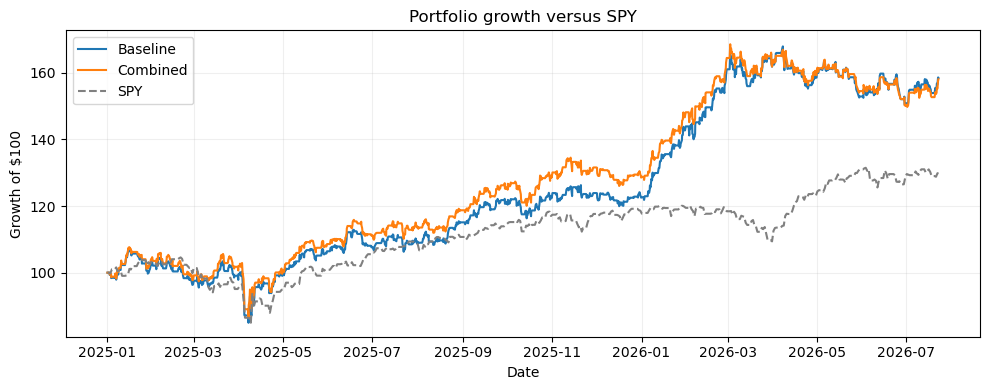

In [2]:
fig, ax = plt.subplots(figsize=(10, 4))
for name, run in runs.items():
    values = run["charts"]["Strategy Equity"]["series"]["Equity"]["values"]
    dates = pd.to_datetime([point[0] for point in values], unit="s", utc=True)
    equity = np.array([point[-1] for point in values])
    ax.plot(dates, 100 * equity / equity[0], label=name.capitalize())
dates = pd.to_datetime([point[0] for point in benchmark], unit="s", utc=True)
ax.plot(dates, 100 * prices / prices[0], label="SPY", color="gray", linestyle="--")
ax.set(title="Portfolio growth versus SPY", ylabel="Growth of $100", xlabel="Date")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


## Findings

The baseline returned **58.45%**, compared with **58.04%** for the combined strategy and **29.71%** for SPY. The fundamental rules reduced return by **0.41 percentage points**, or about **$40,696** on $10 million.

The combined strategy had a smaller maximum drawdown (**19.60% versus 20.70%**), while Sharpe ratios were almost identical (**1.220 versus 1.214**). This is a modest risk/return tradeoff, not a clear improvement.

Both runs had zero rejected orders and no pending rebalance. Each had one cash-limited purchase batch. The margin filter excluded **0 of 12** checked positions, so it made no allocation changes. Differences therefore reflect the P/B tilt and resulting execution, not a demonstrated contribution from the margin filter.

**Conclusion:** the existing portfolio beat SPY, but adding fundamentals did not improve its total return in this period. The small reduction in drawdown does not establish a durable advantage. The margin threshold is left unchanged rather than adjusted to force activity.

The dates were already inspected during research, the test has only four allocation dates, and Project 1's industry weights were optimized on 2022–2024 data. This is a retrospective comparison of selected stocks, not independent validation of a general market strategy.

## Files and reproduction

- `fundamental_backtest.py`: combined strategy; To run, paste into QuantConnect `main.py` and run. An existing `scenario` project parameter overrides `MODE` (3 = combined).
- `baseline_backtest.py`: control strategy; paste into `main.py` for a separate run. It ignores `scenario` parameters.
- `results/`: original exports used above. Dates, fee assumptions, and settlement logic match across both algorithms.